<a href="https://colab.research.google.com/github/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/blob/main/JS06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\r\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\r\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\r\nCobbborough,...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\r\nPort Jason, OH 22070-...",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\r\nPort Jacobville, PR...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


Ukuran data: (500, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:2100: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


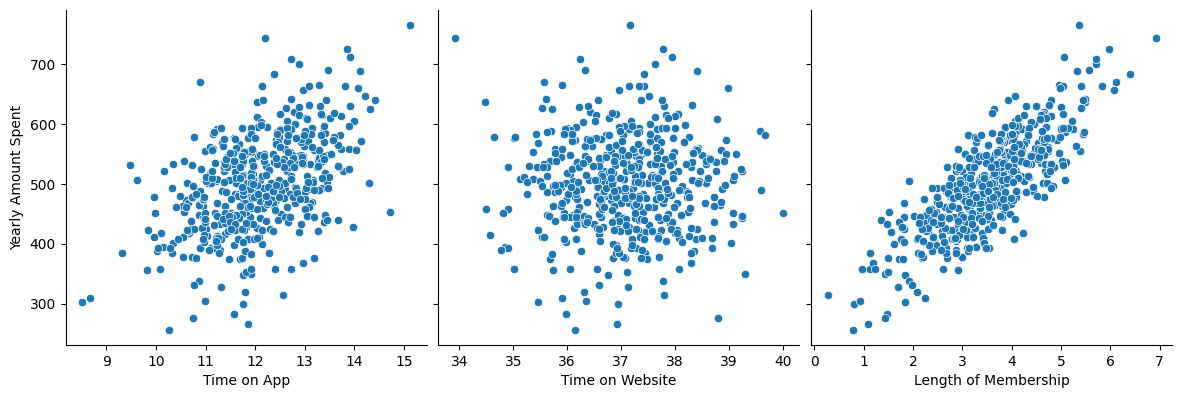

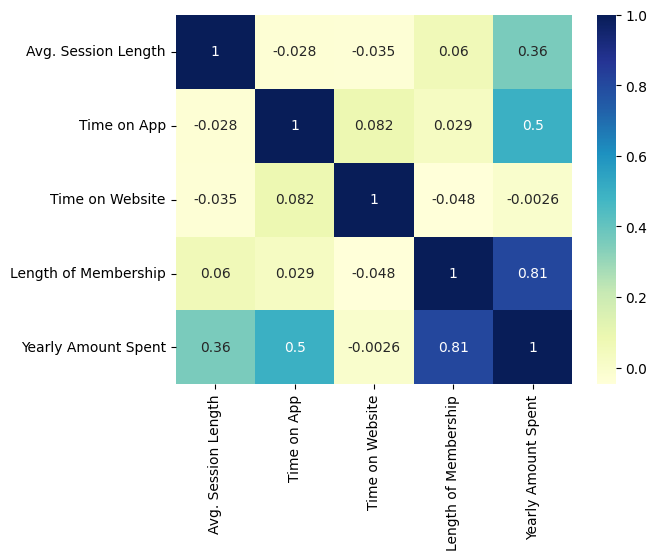

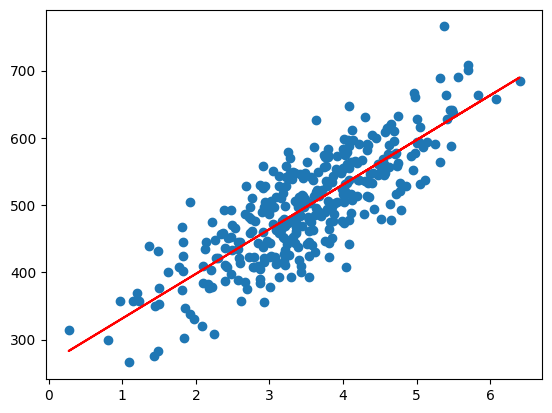

/tmp/ipykernel_787/2402782861.py:50: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(res, bins=15)


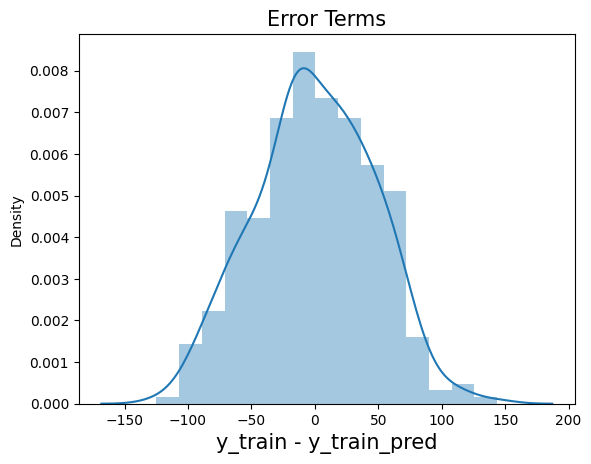

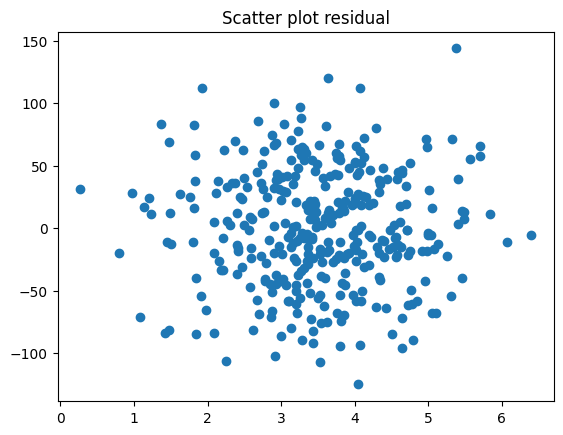

R-squared pada data uji: 0.611948913768747


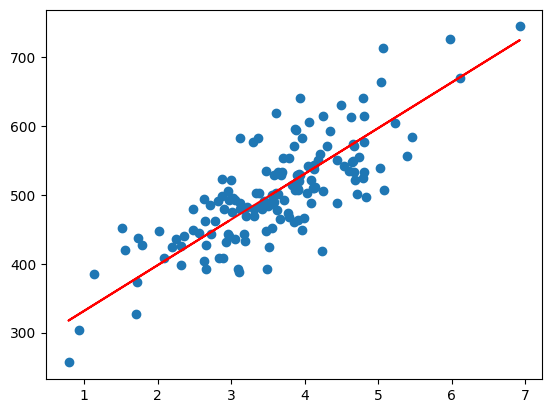

In [1]:
# Praktikum 1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
from sklearn.metrics import r2_score

# Load data
data = pd.read_csv('dataset.csv')

# Eksplorasi data
display(data.head())
print("Ukuran data:", data.shape)
data.info()
display(data.describe())

# Visualisasi hubungan variabel
sns.pairplot(data, x_vars=['Time on App', 'Time on Website', 'Length of Membership'],
             y_vars='Yearly Amount Spent', size=4, aspect=1, kind='scatter')
plt.show()

# Visualisasi korelasi
sns.heatmap(data.corr(numeric_only=True), cmap="YlGnBu", annot=True)
plt.show()

# Pisahkan variabel bebas dan target
X = data['Length of Membership']
y = data['Yearly Amount Spent']

# Split data latih dan uji
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)

# Training model Regresi Linier
X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()

# Visualisasi garis regresi
plt.scatter(X_train, y_train)
plt.plot(X_train, 265.2483 + 66.3015 * X_train, 'r')
plt.show()

# Prediksi dan hitung residual
y_train_pred = lr.predict(X_train_sm)
res = (y_train - y_train_pred)

# Visualisasi residual (Error Terms)
fig = plt.figure()
sns.distplot(res, bins=15)
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=15)
plt.show()

plt.scatter(X_train, res)
plt.title('Scatter plot residual')
plt.show()

# Prediksi pada data uji
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

# Evaluasi R-squared
r_squared = r2_score(y_test, y_test_pred)
print("R-squared pada data uji:", r_squared)

# Visualisasi data uji dan hasil prediksi
plt.scatter(X_test, y_test)
plt.plot(X_test, y_test_pred, 'r')
plt.show()

/tmp/ipykernel_787/492088774.py:25: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  X_grid = np.arange(min(X), max(X), 0.01).reshape(-1, 1)


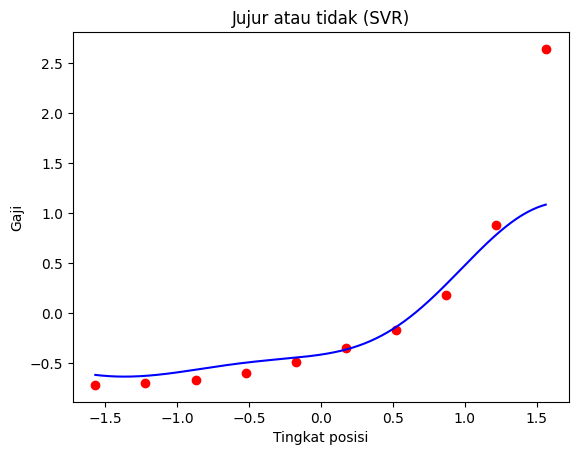

Prediksi Gaji untuk Tingkat Posisi 6.5: [170370.0204065]
MAE: 0.22299274095734414
MSE: 0.24839989293792014
RMSE: 0.4983973243687411
R-squared: 0.7516001070620798


In [2]:
# Praktikum 2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load data
dataset = pd.read_csv('Posisi_gaji.csv')
X = dataset.iloc[:, 1:2].values
y = dataset.iloc[:, 2].values

# Feature Scaling
sc_X = StandardScaler()
sc_y = StandardScaler()
X = sc_X.fit_transform(X.reshape(-1, 1))
y = sc_y.fit_transform(y.reshape(-1, 1))

# Fitting SVR ke dataset
regressor = SVR(kernel='rbf')
regressor.fit(X, y.ravel())

# Visualisasi hasil SVR
X_grid = np.arange(min(X), max(X), 0.01).reshape(-1, 1)
plt.scatter(X, y, color='red')
plt.plot(X_grid, regressor.predict(X_grid), color='blue')
plt.title('Jujur atau tidak (SVR)')
plt.xlabel('Tingkat posisi')
plt.ylabel('Gaji')
plt.show()

# Prediksi untuk tingkat posisi 6.5
tingkat_posisi_prediksi = np.array([[6.5]])
tingkat_posisi_prediksi = sc_X.transform(tingkat_posisi_prediksi)
gaji_prediksi = regressor.predict(tingkat_posisi_prediksi)
gaji_prediksi = sc_y.inverse_transform(gaji_prediksi.reshape(-1, 1))

print("Prediksi Gaji untuk Tingkat Posisi 6.5:", gaji_prediksi[0])

# Evaluasi model SVR
y_actual = y
y_pred = regressor.predict(X)

mae = mean_absolute_error(y_actual, y_pred)
mse = mean_squared_error(y_actual, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_actual, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None


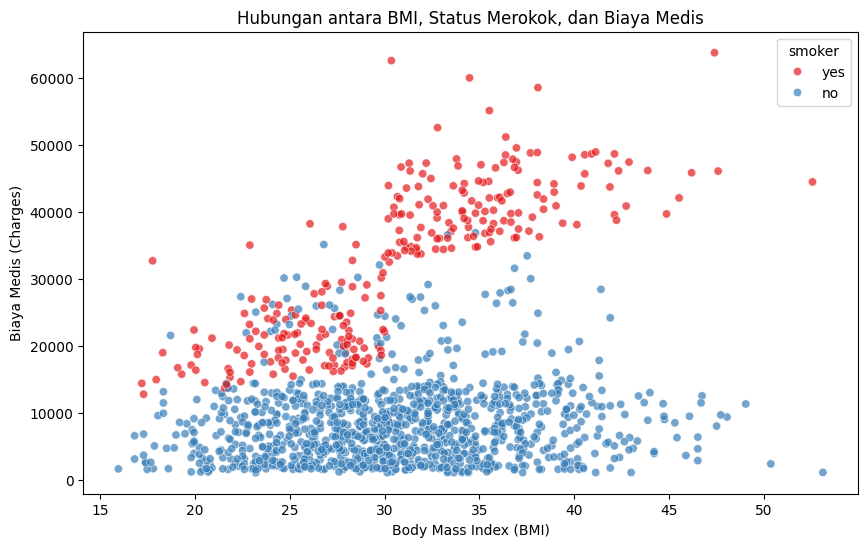

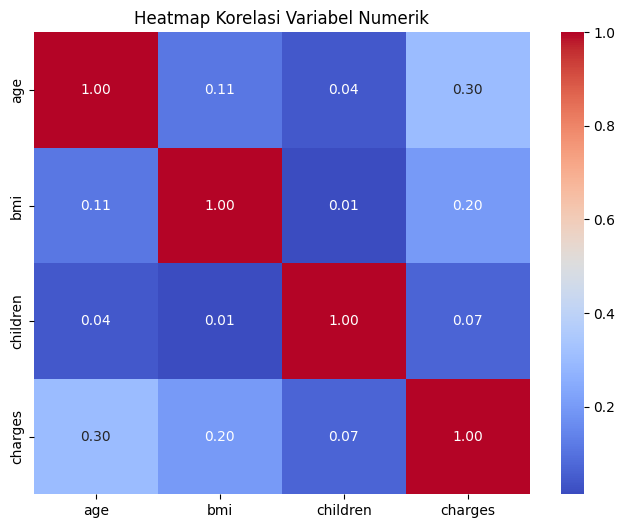


=== Hasil Evaluasi Model Multiple Linear Regression ===
Mean Absolute Error (MAE): 4181.19
Mean Squared Error (MSE): 33596915.85
Root Mean Squared Error (RMSE): 5796.28
R-squared (R2): 0.7836


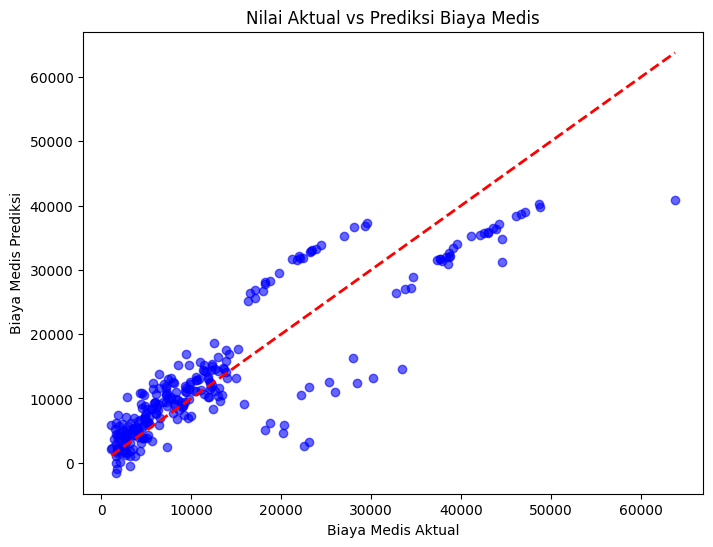

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load Dataset
df = pd.read_csv('insurance.csv')

# Menampilkan informasi awal
display(df.head())
print(df.info())

# --- Visualisasi Data ---
# Visualisasi hubungan BMI dan Biaya Medis (Charges) dipisahkan oleh status perokok
plt.figure(figsize=(10, 6))
sns.scatterplot(x='bmi', y='charges', hue='smoker', data=df, palette='Set1', alpha=0.7)
plt.title('Hubungan antara BMI, Status Merokok, dan Biaya Medis')
plt.xlabel('Body Mass Index (BMI)')
plt.ylabel('Biaya Medis (Charges)')
plt.show()

# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap Korelasi Variabel Numerik')
plt.show()

# --- Preprocessing Data ---
# Encoding variabel kategorikal (sex, smoker, region) menjadi numerik (One-Hot Encoding)
df_encoded = pd.get_dummies(df, drop_first=True)

# 1. Identifikasi Fitur (X) dan Target (y)
X = df_encoded.drop('charges', axis=1)
y = df_encoded['charges']

# 2. Pembagian Data Latih (Train) dan Data Uji (Test) dengan proporsi 80:20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Membuat Model Multiple Linear Regression
mlr_model = LinearRegression()

# 5. Melatih Model dan Melakukan Prediksi
mlr_model.fit(X_train_scaled, y_train)
y_pred = mlr_model.predict(X_test_scaled)

# 6. Evaluasi Model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n=== Hasil Evaluasi Model Multiple Linear Regression ===")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R2): {r2:.4f}")

# Visualisasi Hasil Prediksi vs Nilai Aktual
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='b')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', linewidth=2)
plt.title('Nilai Aktual vs Prediksi Biaya Medis')
plt.xlabel('Biaya Medis Aktual')
plt.ylabel('Biaya Medis Prediksi')
plt.show()

Analisis Hasil Praktikum

Pemahaman Fitur dan Target: Fitur independen yang digunakan mencakup usia, jenis kelamin, BMI, jumlah anak, status perokok, dan wilayah. Variabel charges ditetapkan sebagai target. Kolom kategorikal diubah menjadi dummy variables (biner) agar algoritma Scikit-Learn dapat memprosesnya dengan benar.

Wawasan Visualisasi: Dari scatter plot terlihat pemisahan yang sangat jelas antara perokok dan bukan perokok. Orang yang merokok dengan BMI tinggi (di atas 30) memiliki tagihan medis yang secara signifikan lebih mahal dibandingkan kelompok lainnya. Variabel perokok (smoker_yes) adalah prediktor terkuat untuk menentukan tingginya biaya medis.

Evaluasi Model:

- R-squared (R2) berada di kisaran 0.78 (atau 78%), yang berarti model regresi linier mampu menjelaskan sekitar 78% varians/keragaman dari data biaya medis. Ini merupakan performa yang cukup baik untuk model regresi linier sederhana.

- MAE dan RMSE memberikan representasi rata-rata melesetnya prediksi model (dalam bentuk dolar AS). Garis diagonal merah pada plot Aktual vs Prediksi menunjukkan seberapa dekat hasil prediksi model dengan nilai aslinya. Titik-titik yang menyebar jauh dari garis menandakan adanya error prediksi yang lebih besar pada kasus tagihan medis yang ekstrem.